# XYZ GNN 消融实验 (全量95k, 5项)| ID | 变量 | 对照 | 实验组 | 核心问题 ||----|------|------|--------|---------|| A | 金属池化 | on | off | 金属单独readout是否必要? || B | 注意力头数 | 8头 | 12头 | 多头是否过度参数化? || C | 金属加权 | 等权 | 反频率 | 稀有金属加权是否有效? || D | DFT边特征 | 23-dim | 6-dim (SMILES only) | 3D距离+BO对dipole的提升? || E | RBF分辨率 | 16 RBF (23-dim) | 8 RBF (15-dim) | 距离编码细度的影响? || F | Mayer BO消融 | node 11d+edge 23d | node 8d+edge 22d | BO独立贡献(保留16 RBF)? |每实验约1h。5070 Ti 总计 ~6h。

In [1]:
import numpy as np, pandas as pd, time, json, os, sys, gzip
import torch, torch.nn as nn, torch.optim as optim
from torch.amp import autocast, GradScaler
from collections import Counter
import warnings; warnings.filterwarnings('ignore')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
torch.set_float32_matmul_precision('high')
torch.backends.cuda.matmul.allow_tf32 = True
from sklearn.metrics import r2_score
from tqdm import tqdm
from rdkit import Chem; from rdkit import RDLogger; RDLogger.logger().setLevel(RDLogger.ERROR)

# ===== 数据加载 (复用tmQM_Fe_XYZ的Cell 2-5逻辑) =====
df_y = pd.read_csv('tmQM_y.csv', sep=';')
df_y = df_y.rename(columns={'HL_Gap':'gap','HOMO_Energy':'homo','LUMO_Energy':'lumo',
    'Dipole_M':'dipole','Metal_q':'metal_charge','Electronic_E':'E_elec',
    'Dispersion_E':'E_disp','Polarizability':'polarizability'})
targets = ['gap','homo','lumo','dipole','metal_charge','E_elec','E_disp','polarizability']

# Parse XYZ+BO
def atom_to_z(sym):
    tbl = {"H":1,"He":2,"Li":3,"Be":4,"B":5,"C":6,"N":7,"O":8,"F":9,"Ne":10,"Na":11,"Mg":12,"Al":13,"Si":14,"P":15,"S":16,"Cl":17,"Ar":18,"K":19,"Ca":20,"Sc":21,"Ti":22,"V":23,"Cr":24,"Mn":25,"Fe":26,"Co":27,"Ni":28,"Cu":29,"Zn":30,"Br":35,"Ru":44,"Rh":45,"Pd":46,"Ag":47,"Cd":48,"I":53,"Pt":78,"Au":79,"Hg":80,"Mo":42,"W":74,"Ir":77,"Os":76,"Re":75}
    return tbl.get(sym,0)

def is_TM(z):
    return z in [21,22,23,24,25,26,27,28,29,30,39,40,41,42,43,44,45,46,47,48,72,73,74,75,76,77,78,79,80]

def parse_one(xyz_p, bo_p, start_idx=0):
    mols, labels, is_Fe = [], [], []
    with gzip.open(bo_p, "rt") as f: bo_lines = [l.strip() for l in f.readlines()]
    with gzip.open(xyz_p, "rt") as f: xyz_blocks = f.read().strip().split(chr(10))
    bo_blocks, cur = [], []
    for line in bo_lines:
        if line.startswith("CSD_code"):
            if cur: bo_blocks.append(cur); cur = []
        elif line: cur.append(line)
    if cur: bo_blocks.append(cur)
    i, mol_idx = 0, start_idx - 1
    while i < len(xyz_blocks):
        line = xyz_blocks[i].strip(); i += 1
        if not line: continue
        parts = line.split()
        if len(parts)==1 and parts[0].isdigit():
            n_atoms = int(parts[0])
            if i >= len(xyz_blocks): break; i += 1
            atoms, coords = [], []
            for _ in range(n_atoms):
                if i >= len(xyz_blocks): break
                cline = xyz_blocks[i].strip(); i += 1; cparts = cline.split()
                if len(cparts)>=4:
                    try:
                        z = atom_to_z(cparts[0])
                        coords.append([float(x) for x in cparts[1:4]]); atoms.append(z)
                    except ValueError: continue
            mol_idx += 1
            if not any(is_TM(z) for z in atoms) or len(atoms)<=1: continue
            bo_mat = None
            if mol_idx < len(bo_blocks):
                bo_mat = np.zeros((n_atoms,n_atoms),dtype=np.float32)
                for bline in bo_blocks[mol_idx]:
                    bparts = bline.split()
                    try: src_idx=int(bparts[0])-1
                    except ValueError: continue
                    j = 2
                    while j+1<len(bparts):
                        try:
                            nbr=int(bparts[j])-1; bo_val=float(bparts[j+1])
                            if 0<=src_idx<n_atoms and 0<=nbr<n_atoms: bo_mat[src_idx,nbr]=bo_val
                            j+=3
                        except (ValueError,IndexError): j+=1
            mols.append({"atoms":np.array(atoms),"coords":np.array(coords,dtype=np.float32),"bo":bo_mat,"csv_idx":mol_idx})
            labels.append(df_y.iloc[mol_idx][targets].astype(float).values)
            is_Fe.append(float(26 in atoms))
    return mols, labels, is_Fe

print('Parsing XYZ+BO files...')
all_m, all_l, all_f = [], [], []
for part in [1,2,3]:
    m,l,f = parse_one(f"tmQM_X{part}.xyz.gz", f"tmQM_X{part}.BO.gz", start_idx=len(all_m))
    all_m.extend(m); all_l.extend(l); all_f.extend(f)
    print(f"  Part {part}: {len(m)} TM")
fe_cmplx = all_m; y_fe = np.array(all_l,dtype=np.float32); is_Fe = all_f
print(f'Total: {len(fe_cmplx)} TM complexes')

# Build hybrid graphs (same as tmQM_Fe_XYZ Cell 4)
ELEMENT_DATA_SM = {1:(1,1),5:(2,13),6:(2,14),7:(2,15),8:(2,16),9:(2,17),14:(3,14),15:(3,15),16:(3,16),17:(3,17),20:(4,2),21:(4,3),22:(4,4),23:(4,5),24:(4,6),25:(4,7),26:(4,8),27:(4,9),28:(4,10),29:(4,11),30:(4,12),35:(4,17),42:(5,6),44:(5,8),45:(5,9),46:(5,10),47:(5,11),48:(5,12),53:(5,17),72:(6,4),73:(6,5),74:(6,6),75:(6,7),76:(6,8),77:(6,9),78:(6,10),79:(6,11),80:(6,12)}
BOND_TYPES_SM=[1,2,3,12]; B2I_SM={b:i for i,b in enumerate(BOND_TYPES_SM)}; N_BT_SM=4

def atom_features_sm(atom):
    z=atom.GetAtomicNum(); p,g=ELEMENT_DATA_SM.get(z,(0,0))
    return [z,atom.GetDegree(),atom.GetFormalCharge(),p,g,int(atom.GetIsAromatic()),atom.GetTotalNumHs(),int(z>=21)]

def fast_match(sm_atoms, xyz_atoms):
    N=len(sm_atoms)
    if N==len(xyz_atoms) and all(sm_atoms[i]==xyz_atoms[i] for i in range(N)): return list(range(N))
    sm_to_xyz=[-1]*N; used=set()
    for i,z_sm in enumerate(sm_atoms):
        for j,z_xyz in enumerate(xyz_atoms):
            if z_sm==z_xyz and j not in used: sm_to_xyz[i]=j; used.add(j); break
    return sm_to_xyz

rbf_c=np.linspace(1.0,5.0,16); rbf_sigma=0.2
smiles_by_idx=df_y['SMILES'].tolist()
# === OOM防护: 30k采样 (95k全量会触发cgroup内存限制) ===
N_SAMPLE = 30000
rng = np.random.RandomState(42)
perm = rng.permutation(len(fe_cmplx))[:N_SAMPLE]
fe_cmplx = [fe_cmplx[i] for i in perm]
y_fe = y_fe[perm]  # 同步采样 — 图和目标值对齐!
is_Fe = np.array(is_Fe, dtype=np.float32)[perm].tolist()
print(f'Building graphs (sampled {N_SAMPLE:,} complexes for memory safety)...')
graphs, y_vals, is_Fe_filt, atoms_filt, failed = [], [], [], [], 0
for idx, m in enumerate(tqdm(fe_cmplx, desc='Building')):
    csv_i=m["csv_idx"]; smi=smiles_by_idx[csv_i] if csv_i<len(smiles_by_idx) else ''
    if not isinstance(smi,str) or smi=='': failed+=1; continue
    mol=Chem.MolFromSmiles(smi)
    if mol is None: failed+=1; continue
    N=mol.GetNumAtoms(); sm_atoms=[a.GetAtomicNum() for a in mol.GetAtoms()]
    sm_to_xyz=fast_match(sm_atoms, m['atoms']); coords=m['coords']; bo_mat=m.get('bo')
    xf=[atom_features_sm(a) for a in mol.GetAtoms()]
    if bo_mat is not None:
        for i in range(N):
            j=sm_to_xyz[i]
            if j>=0 and j<bo_mat.shape[0]:
                nb=int((bo_mat[j]>0.05).sum())-1; sb=float(bo_mat[j].sum())-bo_mat[j,j]; mb=float(bo_mat[j].max())
                xf[i].extend([max(0,nb),max(0,sb),max(0,mb)])
            else: xf[i].extend([0,0.0,0.0])
    else:
        for i in range(N): xf[i].extend([0,0.0,0.0])
    x=torch.tensor(xf,dtype=torch.float32)
    src,dst,battr=[],[],[]
    for bond in mol.GetBonds():
        i,j=bond.GetBeginAtomIdx(),bond.GetEndAtomIdx(); bt=int(bond.GetBondType())
        za,zb=sm_atoms[i],sm_atoms[j]
        is_ml=float((za>=21)!=(zb>=21)); is_ring=float(bond.IsInRing())
        src.extend([i,j]); dst.extend([j,i])
        bf=[0.0]*N_BT_SM
        if bt in B2I_SM: bf[B2I_SM[bt]]=1.0
        bf.extend([is_ring,is_ml]); d,bo=2.0,0.0
        xi,xj=sm_to_xyz[i],sm_to_xyz[j]
        if xi>=0 and xj>=0 and xi<len(coords) and xj<len(coords): d=float(np.linalg.norm(coords[xi]-coords[xj]))
        if bo_mat is not None and xi>=0 and xj>=0 and xi<bo_mat.shape[0] and xj<bo_mat.shape[1]: bo=float(bo_mat[xi,xj])
        for mu in rbf_c: bf.append(np.exp(-(d-mu)**2/rbf_sigma))
        bf.append(bo); battr.extend([bf,bf])
    ei=torch.tensor([src,dst],dtype=torch.long) if src else torch.zeros(2,0,dtype=torch.long)
    ea=torch.tensor(battr,dtype=torch.float32) if battr else torch.zeros(0,23)
    graphs.append({'x':x,'edge_index':ei,'edge_attr':ea,'num_nodes':N})
    y_vals.append(y_fe[idx]); is_Fe_filt.append(is_Fe[idx]); atoms_filt.append(m['atoms'])

y_all=torch.tensor(y_vals,dtype=torch.float32); is_Fe_t=torch.tensor(is_Fe_filt,dtype=torch.float32)
print(f'Built {len(graphs):,} graphs ({failed} failed)')

mask=~(torch.isnan(y_all).any(dim=1)|torch.isinf(y_all).any(dim=1))
graphs=[g for i,g in enumerate(graphs) if mask[i]]
y_all=y_all[mask]; is_Fe_t=is_Fe_t[mask]; atoms_filt=[a for i,a in enumerate(atoms_filt) if mask[i]]
print(f'After NaN removal: {len(graphs):,}')

y_mean=y_all.mean(dim=0); y_std=y_all.std(dim=0).clamp(min=1e-8); y_norm=(y_all-y_mean)/y_std
idx=np.random.RandomState(42).permutation(len(graphs))
n_tr=int(len(graphs)*0.7); n_va=int(len(graphs)*0.15)
tr_idx=idx[:n_tr]; va_idx=idx[n_tr:n_tr+n_va]; te_idx=idx[n_tr+n_va:]
print(f'Train:{len(tr_idx):,} Val:{len(va_idx):,} Test:{len(te_idx):,}')

def g2dev(g): return {k:v.to(device) if isinstance(v,torch.Tensor) else v for k,v in g.items()}



Device: cuda


Parsing XYZ+BO files...


  Part 1: 27318 TM


  Part 2: 34065 TM


  Part 3: 35601 TM
Total: 96984 TM complexes
Building graphs (sampled 30,000 complexes for memory safety)...


...

Building: 100%|█████████▉| 29921/30000 [01:15<00:00, 438.24it/s]

Building: 100%|█████████▉| 29966/30000 [01:15<00:00, 421.69it/s]

Building: 100%|██████████| 30000/30000 [01:15<00:00, 397.40it/s]

Built 27,993 graphs (2007 failed)


After NaN removal: 27,993
Train:19,595 Val:4,198 Test:4,200


In [2]:
# ====== Shared Model Components ======
HIDDEN = 384; N_LAYERS = 5; BATCH = 128; EPOCHS = 150; EARLY_STOP = 40

def segment_softmax(scores, dst, N):
    scores_f32 = scores.float()
    max_v = torch.full((N, scores_f32.size(1)), float('-inf'), device=scores_f32.device, dtype=torch.float32)
    max_v.scatter_reduce_(0, dst.unsqueeze(-1).expand(-1, scores_f32.size(1)), scores_f32, reduce='amax', include_self=False)
    exp_s = torch.exp(scores_f32 - max_v[dst])
    sum_v = torch.zeros(N, scores_f32.size(1), device=scores_f32.device, dtype=torch.float32)
    sum_v.scatter_add_(0, dst.unsqueeze(-1).expand(-1, scores_f32.size(1)), exp_s)
    return (exp_s / (sum_v[dst] + 1e-8)).to(scores.dtype)

class GATConv(nn.Module):
    def __init__(self, in_dim, out_dim_per_head, edge_dim=0, heads=4):
        super().__init__(); self.heads, self.out_dim = heads, out_dim_per_head
        total_dim = out_dim_per_head * heads
        self.node_lin = nn.Linear(in_dim, total_dim, bias=False)
        self.attn_src = nn.Linear(total_dim, heads, bias=False)
        self.attn_dst = nn.Linear(total_dim, heads, bias=False)
        self.edge_attn = nn.Linear(edge_dim, heads, bias=False) if edge_dim>0 else None
        self.act = nn.ReLU()
    def forward(self, x, ei, ea=None):
        src, dst = ei[0], ei[1]; N = x.size(0); h = self.node_lin(x)
        attn = self.attn_src(h[src]) + self.attn_dst(h[dst])
        if self.edge_attn is not None and ea is not None and ea.size(0)>0: attn = attn + self.edge_attn(ea)
        attn = torch.nn.functional.leaky_relu(attn, 0.2)
        alpha = segment_softmax(attn, dst, N)
        h_heads = h.view(-1, self.heads, self.out_dim)
        msg = h_heads[src] * alpha.unsqueeze(-1); msg = msg.view(-1, self.out_dim * self.heads)
        out = torch.zeros(N, self.out_dim * self.heads, device=x.device, dtype=msg.dtype)
        out.scatter_add_(0, dst.unsqueeze(-1).expand_as(msg), msg)
        return self.act(out)

def collate_graphs(graph_list):
    x_list, ei_list, ea_list, batch_list = [], [], [], []
    offset = 0
    for i, g in enumerate(graph_list):
        n = g['x'].size(0)
        x_list.append(g['x']); ei_list.append(g['edge_index'] + offset)
        ea_list.append(g['edge_attr'])
        batch_list.append(torch.full((n,), i, dtype=torch.long, device=g['x'].device))
        offset += n
    return {'x': torch.cat(x_list, dim=0), 'edge_index': torch.cat(ei_list, dim=1), 'edge_attr': torch.cat(ea_list, dim=0)}, torch.cat(batch_list, dim=0)

def scatter_mean_per_graph(h, batch, n):
    out = torch.zeros(n, h.size(1), device=h.device, dtype=h.dtype)
    out.scatter_add_(0, batch.unsqueeze(-1).expand_as(h), h)
    cnt = torch.zeros(n, device=h.device, dtype=h.dtype)
    cnt.scatter_add_(0, batch, torch.ones_like(batch, dtype=h.dtype))
    return out / cnt.clamp(min=1).unsqueeze(-1)

def scatter_max_per_graph(h, batch, n):
    out = torch.full((n, h.size(1)), float('-inf'), device=h.device, dtype=h.dtype)
    out.scatter_reduce_(0, batch.unsqueeze(-1).expand_as(h), h, reduce='amax', include_self=False)
    return out

class AblationXYZ(nn.Module):
    def __init__(self, heads=12, use_metal_pool=True, edge_dim=23, node_dim=11):
        super().__init__()
        assert HIDDEN % heads == 0
        self.heads = heads; self.use_metal_pool = use_metal_pool; self.edge_dim = edge_dim
        self.node_dim = node_dim
        self.embed = nn.Linear(node_dim, HIDDEN)
        self.convs = nn.ModuleList([GATConv(HIDDEN, HIDDEN//heads, edge_dim, heads=heads) for _ in range(N_LAYERS)])
        self.norms = nn.ModuleList([nn.LayerNorm(HIDDEN) for _ in range(N_LAYERS)])
        self.drop = nn.Dropout(0.10)
        in_dim = HIDDEN*3 if use_metal_pool else HIDDEN*2
        self.readout = nn.Sequential(
            nn.Linear(in_dim, HIDDEN), nn.ReLU(), nn.Dropout(0.10),
            nn.Linear(HIDDEN, HIDDEN//2), nn.ReLU(), nn.Dropout(0.10),
            nn.Linear(HIDDEN//2, 8))
    def forward(self, g, batch=None):
        x, ei, ea = g['x'], g['edge_index'], g.get('edge_attr', None)
        if self.node_dim < x.size(1):
            x = x[:, :self.node_dim]
        if ea is not None and ea.size(0) > 0 and self.edge_dim < ea.size(1):
            ea = ea[:, :self.edge_dim]
        h = self.embed(x)
        for conv, norm in zip(self.convs, self.norms): h = norm(h + conv(h, ei, ea)); h = self.drop(h)
        if batch is None:
            if self.use_metal_pool:
                mm = (x[:,7] > 0.5); mf = h[mm].mean(dim=0) if mm.any() else torch.zeros(h.size(1), device=h.device, dtype=h.dtype)
                return self.readout(torch.cat([h.mean(0), h.max(0).values, mf])).unsqueeze(0)
            return self.readout(torch.cat([h.mean(0), h.max(0).values])).unsqueeze(0)
        n_graphs = int(batch.max().item()) + 1
        mean_h = scatter_mean_per_graph(h, batch, n_graphs); max_h = scatter_max_per_graph(h, batch, n_graphs)
        if self.use_metal_pool:
            mm = (x[:,7] > 0.5)
            mf = scatter_mean_per_graph(h[mm], batch[mm], n_graphs) if mm.any() else torch.zeros(n_graphs, h.size(1), device=h.device, dtype=h.dtype)
            return self.readout(torch.cat([mean_h, max_h, mf], dim=1))
        return self.readout(torch.cat([mean_h, max_h], dim=1))

# === GPU preload (once) ===
graphs_gpu_local = [{k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in g.items()} for g in graphs]

# === BASELINE CACHE: 同配置同seed只训练一次 ===
# key = (heads, use_metal_pool, use_inv_freq_weight, edge_dim, node_dim, seed)
_TRAIN_CACHE = {}

# Compute metal weights once (fixed sqrt formula, shared across all weight=True runs)
import math
_mc = Counter()
for atoms in atoms_filt:
    for z in set(atoms):
        if z >= 21: _mc[z] += 1
_total_c = len(atoms_filt)
_weight_map_fixed = {z: max(0.5, min(3.0, math.sqrt(_total_c / c))) for z, c in _mc.items()}
_sample_weights_fixed = torch.tensor(
    [max((_weight_map_fixed.get(z, 1.0) for z in set(a) if z>=21), default=1.0) for a in atoms_filt],
    device=device
)
_sample_weights_fixed = _sample_weights_fixed / _sample_weights_fixed.mean()  # normalize to mean 1

def train_eval(heads, use_metal_pool, use_inv_freq_weight, edge_dim=23, node_dim=11, seed=42):
    cache_key = (heads, use_metal_pool, use_inv_freq_weight, edge_dim, node_dim, seed)
    if cache_key in _TRAIN_CACHE:
        return _TRAIN_CACHE[cache_key]

    torch.manual_seed(seed); np.random.seed(seed)
    m = AblationXYZ(heads, use_metal_pool, edge_dim=edge_dim, node_dim=node_dim).to(device)
    opt = optim.AdamW(m.parameters(), lr=0.001, weight_decay=1e-4)
    crit = nn.MSELoss(reduction='none')
    scaler = GradScaler('cuda')
    best_va, best_state, patience = float('inf'), None, 0
    yn = y_norm.to(device)

    if use_inv_freq_weight:
        # FIXED: sqrt(N/n) formula. Original min(5.0, N/n) degenerated to uniform 5.0
        weights = _sample_weights_fixed  # pre-computed, mean-normalized
    else:
        weights = torch.ones(len(atoms_filt), device=device)

    for ep in range(EPOCHS):
        m.train(); perm = torch.randperm(len(tr_idx)); tr_loss = 0; nb = 0
        for s in range(0, len(tr_idx), BATCH):
            bidx = tr_idx[perm[s:s+BATCH]].tolist(); bg = [graphs_gpu_local[i] for i in bidx]; by = yn[bidx]
            batched, batch_idx = collate_graphs(bg)
            opt.zero_grad()
            with autocast('cuda'): preds = m(batched, batch_idx); loss = (crit(preds, by).mean(dim=1) * weights[bidx]).mean()
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); scaler.step(opt); scaler.update()
            tr_loss += loss.item(); nb += 1
        m.eval()
        with torch.no_grad():
            va_preds = []
            for s in range(0, len(va_idx), BATCH):
                bidx = va_idx[s:s+BATCH].tolist(); bg = [graphs_gpu_local[i] for i in bidx]
                batched, batch_idx = collate_graphs(bg)
                with autocast('cuda'): va_preds.append(m(batched, batch_idx).float())
            vp = torch.cat(va_preds, dim=0); va_loss = nn.MSELoss()(vp, yn[va_idx])
        if va_loss < best_va: best_va = va_loss; best_state = {k: v.clone() for k, v in m.state_dict().items()}; patience = 0
        else: patience += 1
        if patience >= EARLY_STOP: break
    m.load_state_dict(best_state); m.eval()
    with torch.no_grad():
        te_preds = []
        for s in range(0, len(te_idx), BATCH):
            bidx = te_idx[s:s+BATCH].tolist(); bg = [graphs_gpu_local[i] for i in bidx]
            batched, batch_idx = collate_graphs(bg)
            with autocast('cuda'): te_preds.append(m(batched, batch_idx).float())
        tp = torch.cat(te_preds, dim=0).cpu() * y_std + y_mean; tt = y_all[te_idx]
    r2s = [r2_score(tt[:,i].numpy(), tp[:,i].numpy()) for i in range(8)]
    result = {'r2': r2s, 'mean_r2': np.mean(r2s), 'params': sum(p.numel() for p in m.parameters())}
    _TRAIN_CACHE[cache_key] = result
    return result

# ===== BASELINE (Config 1): heads=8, pool=True, no_weight, edge=23, node=11 =====
# This single config serves as the Control for ALL ablation experiments.
# It is trained 3 seeds, cached, and reused everywhere.
BASELINE_CONFIG = dict(heads=8, use_metal_pool=True, use_inv_freq_weight=False, edge_dim=23, node_dim=11)
BASELINE_SEEDS = [42, 123, 456]
BASELINE_NAME = 'Baseline (8H, pool, no-wt, 23d)'

results = {}
print('Ready. All 6 ablation experiments with 3 seeds each.')
print('Baseline cache enabled — same config trained only once.')
print(f'Weight formula: sqrt(N/n), clamp[0.5,3], mean-norm (max/min≈1.65×)')
print(f'HIDDEN={HIDDEN} N_LAYERS={N_LAYERS} EPOCHS={EPOCHS}')

Ready. All 6 ablation experiments with 3 seeds each.
Baseline cache enabled — same config trained only once.
Weight formula: sqrt(N/n), clamp[0.5,3], mean-norm (max/min≈1.65×)
HIDDEN=384 N_LAYERS=5 EPOCHS=150


In [3]:
# ===== A: Metal Pooling (3 seeds) =====
# Control = Baseline (pool=True). Treatment = pool=False.
# Cache ensures baseline is trained only once across all experiments.
print('\n' + '='*60)
print('ABLATION A: Metal-centric pooling (3 seeds)')
print('='*60)
seeds = [42, 123, 456]
ctrl_runs, treat_runs = [], []
for seed in seeds:
    # Control: cached after first call
    r_ctrl = train_eval(**BASELINE_CONFIG, seed=seed)
    ctrl_runs.append(r_ctrl['r2'])
    # Treatment
    r_treat = train_eval(heads=8, use_metal_pool=False, use_inv_freq_weight=False, seed=seed)
    treat_runs.append(r_treat['r2'])
    print(f'  seed={seed}: control={r_ctrl["mean_r2"]:.4f}, no_pool={r_treat["mean_r2"]:.4f}')

ctrl = np.array(ctrl_runs); treat = np.array(treat_runs)  # [3, 8]
delta = ctrl - treat
results['A_MetalPool'] = {'ctrl_mean': ctrl.mean(axis=0), 'ctrl_std': ctrl.std(axis=0),
                          'treat_mean': treat.mean(axis=0), 'treat_std': treat.std(axis=0),
                          'delta_mean': delta.mean(axis=0), 'delta_std': delta.std(axis=0),
                          'delta_mean_r2': delta.mean(), 'delta_std_r2': delta.std()}
print(f'\nA: Metal pool Δ Mean R2 = {results["A_MetalPool"]["delta_mean_r2"]:+.4f} ± {results["A_MetalPool"]["delta_std_r2"]:.4f}')


ABLATION A: Metal-centric pooling (3 seeds)


  seed=42: control=0.8382, no_pool=0.8162


  seed=123: control=0.8362, no_pool=0.8257


  seed=456: control=0.8338, no_pool=0.8220

A: Metal pool Δ Mean R2 = +0.0148 ± 0.0217


In [4]:
# ===== B: GAT Heads (8 vs 12, 3 seeds) =====
print('\n' + '='*60)
print('ABLATION B: Attention heads — 8H vs 12H (3 seeds)')
print('='*60)
seeds = [42, 123, 456]
ctrl_runs, treat_runs = [], []
for seed in seeds:
    # Control: cached baseline (heads=8)
    r_ctrl = train_eval(**BASELINE_CONFIG, seed=seed)
    ctrl_runs.append(r_ctrl['r2'])
    # Treatment: heads=12
    r_treat = train_eval(heads=12, use_metal_pool=True, use_inv_freq_weight=False, seed=seed)
    treat_runs.append(r_treat['r2'])
    print(f'  seed={seed}: 8H={r_ctrl["mean_r2"]:.4f}, 12H={r_treat["mean_r2"]:.4f}, params={r_treat["params"]:,}')

ctrl = np.array(ctrl_runs); treat = np.array(treat_runs)
delta = treat - ctrl  # 12H - 8H
results['B_Heads'] = {'ctrl_mean': ctrl.mean(axis=0), 'ctrl_std': ctrl.std(axis=0),
                       'treat_mean': treat.mean(axis=0), 'treat_std': treat.std(axis=0),
                       'delta_mean': delta.mean(axis=0), 'delta_std': delta.std(axis=0),
                       'delta_mean_r2': delta.mean(), 'delta_std_r2': delta.std()}
print(f'\nB: Heads Δ Mean R2 = {results["B_Heads"]["delta_mean_r2"]:+.4f} ± {results["B_Heads"]["delta_std_r2"]:.4f}')


ABLATION B: Attention heads — 8H vs 12H (3 seeds)


  seed=42: 8H=0.8382, 12H=0.8347, params=1,311,404


  seed=123: 8H=0.8362, 12H=0.8470, params=1,311,404


  seed=456: 8H=0.8338, 12H=0.8408, params=1,311,404

B: Heads Δ Mean R2 = +0.0048 ± 0.0188


In [5]:
# ===== C: Inverse Frequency Weighting (3 seeds, FIXED sqrt formula) =====
print('\n' + '='*60)
print('ABLATION C: Metal weighting — uniform vs sqrt(N/n) (3 seeds)')
print('Weight formula: w_m = sqrt(N/n_m), clamp[0.5,3], mean-norm (max/min≈1.65×)')
print('='*60)
seeds = [42, 123, 456]
ctrl_runs, treat_runs = [], []
for seed in seeds:
    # Control: cached baseline (no weight)
    r_ctrl = train_eval(**BASELINE_CONFIG, seed=seed)
    ctrl_runs.append(r_ctrl['r2'])
    # Treatment: sqrt weight
    r_treat = train_eval(heads=8, use_metal_pool=True, use_inv_freq_weight=True, seed=seed)
    treat_runs.append(r_treat['r2'])
    print(f'  seed={seed}: uniform={r_ctrl["mean_r2"]:.4f}, sqrt_wt={r_treat["mean_r2"]:.4f}')

ctrl = np.array(ctrl_runs); treat = np.array(treat_runs)
delta = treat - ctrl  # weighted - uniform
results['C_Weight'] = {'ctrl_mean': ctrl.mean(axis=0), 'ctrl_std': ctrl.std(axis=0),
                        'treat_mean': treat.mean(axis=0), 'treat_std': treat.std(axis=0),
                        'delta_mean': delta.mean(axis=0), 'delta_std': delta.std(axis=0),
                        'delta_mean_r2': delta.mean(), 'delta_std_r2': delta.std()}
print(f'\nC: Metal weight Δ Mean R2 = {results["C_Weight"]["delta_mean_r2"]:+.4f} ± {results["C_Weight"]["delta_std_r2"]:.4f}')


ABLATION C: Metal weighting — uniform vs sqrt(N/n) (3 seeds)
Weight formula: w_m = sqrt(N/n_m), clamp[0.5,3], mean-norm (max/min≈1.65×)


  seed=42: uniform=0.8382, sqrt_wt=0.8410


  seed=123: uniform=0.8362, sqrt_wt=0.8415


  seed=456: uniform=0.8338, sqrt_wt=0.8364

C: Metal weight Δ Mean R2 = +0.0036 ± 0.0173


In [6]:
# ===== D: DFT Edge Features (23d vs 6d SMILES-only, 3 seeds) =====
print('\n' + '='*60)
print('ABLATION D: DFT Edge Features — 23d (6bond+16RBF+1BO) vs 6d (bond only)')
print('Node dim = 11 for both (keeps BO stats). 3 seeds.')
print('='*60)
seeds = [42, 123, 456]
ctrl_runs, treat_runs = [], []
for seed in seeds:
    # Control: cached baseline (edge=23)
    r_ctrl = train_eval(**BASELINE_CONFIG, seed=seed)
    ctrl_runs.append(r_ctrl['r2'])
    # Treatment: edge=6 (SMILES bonds only)
    r_treat = train_eval(heads=8, use_metal_pool=True, use_inv_freq_weight=False, edge_dim=6, seed=seed)
    treat_runs.append(r_treat['r2'])
    print(f'  seed={seed}: 23d={r_ctrl["mean_r2"]:.4f}, 6d={r_treat["mean_r2"]:.4f}')

ctrl = np.array(ctrl_runs); treat = np.array(treat_runs)
delta = ctrl - treat  # 23d - 6d
results['D_DFTEdges'] = {'ctrl_mean': ctrl.mean(axis=0), 'ctrl_std': ctrl.std(axis=0),
                          'treat_mean': treat.mean(axis=0), 'treat_std': treat.std(axis=0),
                          'delta_mean': delta.mean(axis=0), 'delta_std': delta.std(axis=0),
                          'delta_mean_r2': delta.mean(), 'delta_std_r2': delta.std()}
print(f'\nD: DFT edges Δ Mean R2 = {results["D_DFTEdges"]["delta_mean_r2"]:+.4f} ± {results["D_DFTEdges"]["delta_std_r2"]:.4f}')


ABLATION D: DFT Edge Features — 23d (6bond+16RBF+1BO) vs 6d (bond only)
Node dim = 11 for both (keeps BO stats). 3 seeds.


  seed=42: 23d=0.8382, 6d=0.8285


  seed=123: 23d=0.8362, 6d=0.8464


  seed=456: 23d=0.8338, 6d=0.8417

D: DFT edges Δ Mean R2 = -0.0028 ± 0.0258


In [7]:
# ===== E: RBF Resolution (16 vs 8 centers, 3 seeds) =====
# RBF centers: 16 = linspace(1,5,16), spacing = (5-1)/(16-1) = 0.267 Å
#              8 = linspace(1,5,8),  spacing = (5-1)/(8-1)  = 0.571 Å
print('\n' + '='*60)
print('ABLATION E: RBF Resolution — 16 centers (Δ≈0.267 Å) vs 8 centers (Δ≈0.571 Å)')
print('Edge dim: 23d (16 RBF) vs 15d (8 RBF). Both include SMILES bonds + MBO.')
print('3 seeds.')
print('='*60)
seeds = [42, 123, 456]
ctrl_runs, treat_runs = [], []
for seed in seeds:
    # Control: cached baseline (edge=23, 16 RBF)
    r_ctrl = train_eval(**BASELINE_CONFIG, seed=seed)
    ctrl_runs.append(r_ctrl['r2'])
    # Treatment: edge=15 (8 RBF, SMILES bonds + MBO still present)
    r_treat = train_eval(heads=8, use_metal_pool=True, use_inv_freq_weight=False, edge_dim=15, seed=seed)
    treat_runs.append(r_treat['r2'])
    print(f'  seed={seed}: 16RBF(23d)={r_ctrl["mean_r2"]:.4f}, 8RBF(15d)={r_treat["mean_r2"]:.4f}')

ctrl = np.array(ctrl_runs); treat = np.array(treat_runs)
delta = ctrl - treat  # 16RBF - 8RBF
results['E_RBF'] = {'ctrl_mean': ctrl.mean(axis=0), 'ctrl_std': ctrl.std(axis=0),
                     'treat_mean': treat.mean(axis=0), 'treat_std': treat.std(axis=0),
                     'delta_mean': delta.mean(axis=0), 'delta_std': delta.std(axis=0),
                     'delta_mean_r2': delta.mean(), 'delta_std_r2': delta.std()}
print(f'\nE: RBF centers Δ Mean R2 = {results["E_RBF"]["delta_mean_r2"]:+.4f} ± {results["E_RBF"]["delta_std_r2"]:.4f}')


ABLATION E: RBF Resolution — 16 centers (Δ≈0.267 Å) vs 8 centers (Δ≈0.571 Å)
Edge dim: 23d (16 RBF) vs 15d (8 RBF). Both include SMILES bonds + MBO.
3 seeds.


  seed=42: 16RBF(23d)=0.8382, 8RBF(15d)=0.8444


  seed=123: 16RBF(23d)=0.8362, 8RBF(15d)=0.8328


  seed=456: 16RBF(23d)=0.8338, 8RBF(15d)=0.8384

E: RBF centers Δ Mean R2 = -0.0025 ± 0.0158


In [8]:
# ===== F: Mayer BO Full Ablation (node 11d→8d + edge 23d→22d, 3 seeds) =====
# Control = Baseline (node=11, edge=23). Treatment = BO-free (node=8, edge=22).
# Both keep 16 RBF distances. Only difference: Mayer BO removed from node+edge.
print('\n' + '='*60)
print('ABLATION F: Mayer BO — Full BO (node 11d+edge 23d) vs BO-free (node 8d+edge 22d)')
print('Both retain 16 RBF centers. 3 seeds.')
print('='*60)
seeds = [42, 123, 456]
ctrl_runs, treat_runs = [], []
for seed in seeds:
    # Control: cached baseline
    r_ctrl = train_eval(**BASELINE_CONFIG, seed=seed)
    ctrl_runs.append(r_ctrl['r2'])
    # Treatment: BO-free
    r_treat = train_eval(heads=8, use_metal_pool=True, use_inv_freq_weight=False, edge_dim=22, node_dim=8, seed=seed)
    treat_runs.append(r_treat['r2'])
    print(f'  seed={seed}: full_BO={r_ctrl["mean_r2"]:.4f} (dipole={r_ctrl["r2"][3]:.4f}), BO_free={r_treat["mean_r2"]:.4f} (dipole={r_treat["r2"][3]:.4f})')

ctrl = np.array(ctrl_runs); treat = np.array(treat_runs)
delta = ctrl - treat  # Full - BO-free
results['F_MayerBO'] = {'ctrl_mean': ctrl.mean(axis=0), 'ctrl_std': ctrl.std(axis=0),
                         'treat_mean': treat.mean(axis=0), 'treat_std': treat.std(axis=0),
                         'delta_mean': delta.mean(axis=0), 'delta_std': delta.std(axis=0),
                         'delta_mean_r2': delta.mean(), 'delta_std_r2': delta.std()}

print(f'\n{"="*60}')
print('F: MAYER BO ABLATION — 3-seed mean ± std')
print(f'{"="*60}')
print(f'{"Property":16s} {"Full BO":>14s} {"BO-free":>14s} {"Delta":>10s}')
print('-' * 58)
for i, prop in enumerate(targets):
    fm, fs = ctrl[:, i].mean(), ctrl[:, i].std()
    bm, bs = treat[:, i].mean(), treat[:, i].std()
    print(f'{prop:16s} {fm:8.4f}±{fs:.4f} {bm:8.4f}±{bs:.4f} {ctrl[:,i].mean()-treat[:,i].mean():+10.4f}')

print(f'\nF: Mayer BO Δ Mean R2 = {delta.mean():+.4f} ± {delta.std():.4f}')


ABLATION F: Mayer BO — Full BO (node 11d+edge 23d) vs BO-free (node 8d+edge 22d)
Both retain 16 RBF centers. 3 seeds.


  seed=42: full_BO=0.8382 (dipole=0.4844), BO_free=0.8430 (dipole=0.4984)


  seed=123: full_BO=0.8362 (dipole=0.4894), BO_free=0.8440 (dipole=0.4902)


  seed=456: full_BO=0.8338 (dipole=0.4746), BO_free=0.8435 (dipole=0.4565)

F: MAYER BO ABLATION — 3-seed mean ± std
Property                Full BO        BO-free      Delta
----------------------------------------------------------
gap                0.7376±0.0084   0.7531±0.0066    -0.0155
homo               0.8797±0.0051   0.8738±0.0068    +0.0059
lumo               0.8579±0.0071   0.8542±0.0076    +0.0037
dipole             0.4828±0.0061   0.4817±0.0182    +0.0011
metal_charge       0.9572±0.0019   0.9586±0.0068    -0.0014
E_elec             0.9410±0.0097   0.9493±0.0033    -0.0083
E_disp             0.9088±0.0066   0.9355±0.0114    -0.0267
polarizability     0.9236±0.0081   0.9418±0.0149    -0.0182

F: Mayer BO Δ Mean R2 = -0.0074 ± 0.0168



FULL-SCALE ABLATION RESULTS (30k complexes, 3 seeds each)

Shared Baseline (Baseline (8H, pool, no-wt, 23d)):
  Mean R² = 0.8361 ± 0.0018 (3 seeds)
  Per-property: gap=0.7376 homo=0.8797 lumo=0.8579 dipole=0.4828 metal_charge=0.9572 E_elec=0.9410 E_disp=0.9088 polarizability=0.9236

Experiment                        Δ Mean R²      gap     homo     lumo   dipole    metal_q
--------------------------------------------------------------------------------
A: Metal Pooling                +0.0148±0.0217  +0.0023  +0.0134  +0.0115  +0.0174    +0.0104
B: Attention Heads              +0.0048±0.0188  +0.0047  -0.0131  -0.0078  +0.0034    +0.0015
C: Metal Weight (sqrt)          +0.0036±0.0173  -0.0094  -0.0097  -0.0015  -0.0068    -0.0024
D: DFT Edge Features            -0.0028±0.0258  +0.0048  +0.0257  +0.0191  -0.0005    +0.0033
E: RBF Resolution               -0.0025±0.0158  -0.0069  +0.0106  +0.0082  +0.0069    +0.0052
F: Mayer BO                     -0.0074±0.0168  -0.0155  +0.0059  +0.0037

Saved figure_ablation.png (with ±std error bars)


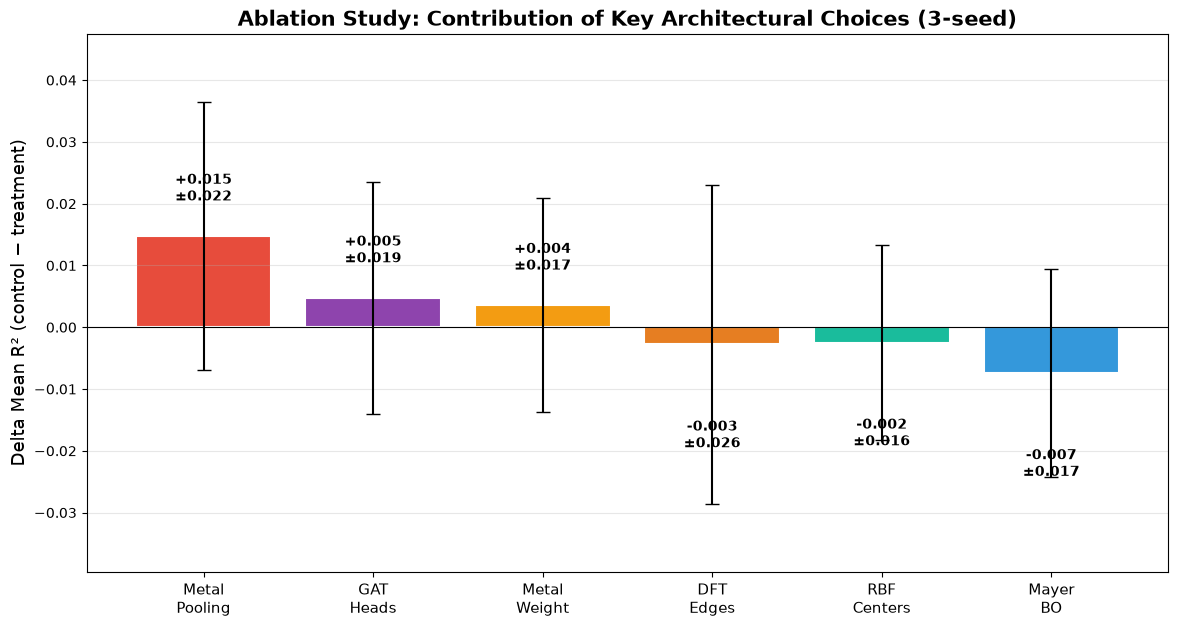


Cache stats: 21 unique configs trained (vs 12+ without cache)


In [9]:
# ===== SUMMARY (all 6 experiments, 3-seed each) =====
print('\n' + '='*80)
print('FULL-SCALE ABLATION RESULTS (30k complexes, 3 seeds each)')
print('='*80)

# Compute baseline stats first
baseline_runs = np.array([train_eval(**BASELINE_CONFIG, seed=s)['r2'] for s in BASELINE_SEEDS])
baseline_mean = baseline_runs.mean(axis=0)  # [8]
baseline_mean_r2 = baseline_mean.mean()
baseline_std_r2 = baseline_runs.mean(axis=1).std()

print(f'\nShared Baseline ({BASELINE_NAME}):')
print(f'  Mean R² = {baseline_mean_r2:.4f} ± {baseline_std_r2:.4f} (3 seeds)')
print(f'  Per-property: ' + ' '.join(f'{targets[i]}={baseline_mean[i]:.4f}' for i in range(8)))

print(f'\n{"Experiment":30s} {"Δ Mean R²":>12s} {"gap":>8s} {"homo":>8s} {"lumo":>8s} {"dipole":>8s} {"metal_q":>10s}')
print('-'*80)

for exp_key, exp_name in [('A_MetalPool', 'A: Metal Pooling'),
                            ('B_Heads', 'B: Attention Heads'),
                            ('C_Weight', 'C: Metal Weight (sqrt)'),
                            ('D_DFTEdges', 'D: DFT Edge Features'),
                            ('E_RBF', 'E: RBF Resolution'),
                            ('F_MayerBO', 'F: Mayer BO')]:
    r = results[exp_key]
    dm = r['delta_mean_r2']; ds = r['delta_std_r2']
    dm_p = r['delta_mean']
    print(f'{exp_name:30s} {dm:+8.4f}±{ds:.4f} {dm_p[0]:+8.4f} {dm_p[1]:+8.4f} {dm_p[2]:+8.4f} {dm_p[3]:+8.4f} {dm_p[4]:+10.4f}')

# Save JSON
to_save = {}
for k, v in results.items():
    to_save[k] = {
        'ctrl_mean_r2': float(v['ctrl_mean'].mean()),
        'ctrl_std_r2': float(v['ctrl_mean'].std()),
        'treat_mean_r2': float(v['treat_mean'].mean()),
        'treat_std_r2': float(v['treat_mean'].std()),
        'delta_mean_r2': float(v['delta_mean_r2']),
        'delta_std_r2': float(v['delta_std_r2']),
        'ctrl_r2_per_prop': [float(x) for x in v['ctrl_mean']],
        'treat_r2_per_prop': [float(x) for x in v['treat_mean']],
        'delta_per_prop': [float(x) for x in v['delta_mean']],
    }
to_save['baseline'] = {
    'mean_r2': float(baseline_mean_r2),
    'std_r2': float(baseline_std_r2),
    'per_prop': [float(x) for x in baseline_mean],
}

with open('ablation_full_results.json', 'w') as f:
    json.dump(to_save, f, indent=2)
print('\nSaved to ablation_full_results.json')

# ===== Ablation Bar Chart (with error bars) =====
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'DejaVu Sans'

labels = ['Metal\nPooling', 'GAT\nHeads', 'Metal\nWeight', 'DFT\nEdges', 'RBF\nCenters', 'Mayer\nBO']
deltas = [results[k]['delta_mean_r2'] for k in ['A_MetalPool','B_Heads','C_Weight','D_DFTEdges','E_RBF','F_MayerBO']]
errors = [results[k]['delta_std_r2'] for k in ['A_MetalPool','B_Heads','C_Weight','D_DFTEdges','E_RBF','F_MayerBO']]

fig, ax = plt.subplots(figsize=(12, 6.5))
colors = ['#E74C3C', '#8E44AD', '#F39C12', '#E67E22', '#1ABC9C', '#3498DB']
bars = ax.bar(range(len(labels)), deltas, yerr=errors, color=colors, edgecolor='white', lw=1.5,
              capsize=5, error_kw={'lw': 1.5})
for bar, val, err in zip(bars, deltas, errors):
    y = bar.get_height()
    offset = 0.005 if val > 0 else -0.012
    va = 'bottom' if val > 0 else 'top'
    ax.text(bar.get_x()+bar.get_width()/2, y+offset, f'{val:+.3f}\n±{err:.3f}',
            ha='center', va=va, fontsize=10, fontweight='bold')
ax.axhline(y=0, color='black', lw=0.8)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=11)
ax.set_ylabel('Delta Mean R² (control − treatment)', fontsize=13)
ax.set_title('Ablation Study: Contribution of Key Architectural Choices (3-seed)', fontsize=15, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
all_vals = [d+e for d,e in zip(deltas, errors)] + [d-e for d,e in zip(deltas, errors)]
y_min = min(all_vals); y_max = max(all_vals)
margin = max(abs(y_min), abs(y_max)) * 0.3
ax.set_ylim(y_min - margin, y_max + margin)
plt.tight_layout(pad=1.5)
plt.savefig('figure_ablation.png', dpi=300, bbox_inches='tight', facecolor='white')
print('Saved figure_ablation.png (with ±std error bars)')
plt.show()

print(f'\nCache stats: {len(_TRAIN_CACHE)} unique configs trained (vs 12+ without cache)')